<a href="https://colab.research.google.com/github/minhphu12-oc/basic-python/blob/sklearn-project-for-machine-learning/project_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PROJECT 2

Bước 1 : Lấy data có sẵn của gg colab đã chia sẵn train test

1.1 lấy data tập train

In [ ]:
import pandas as pd
file_path1 = '/content/sample_data/mnist_train_small.csv'
df_local1 = pd.read_csv(file_path1, header=None)
print(f"Kích thước file: {df_local1.shape}")
display(df_local1.head())

Kích thước file: (20000, 785)


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,6,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


1.2 lấy data tập test

In [ ]:
import pandas as pd
file_path2 = '/content/sample_data/mnist_test.csv'
df_local2 = pd.read_csv(file_path2, header=None)
print(f"Kích thước file: {df_local2.shape}")
display(df_local2.head())

Kích thước file: (10000, 785)


,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,7,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


Bước 2 : tiền xử lí dữ liệu

2.1 chia dữ liệu trên tập train

In [ ]:
x_train = df_local1.iloc[:, 1:]
y_train = df_local1.iloc[:, 0]
x_test = df_local2.iloc[:, 1:]
y_test = df_local2.iloc[:, 0]
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(20000, 784)
(20000,)
(10000, 784)
(10000,)


2.1 chia dữ liệu thành các batch và xây dựng model

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from torchvision import transforms
import numpy as np

x_train_tensor = torch.tensor(x_train.values, dtype=torch.float32)
x_test_tensor = torch.tensor(x_test.values, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train.values, dtype=torch.long)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.long)

train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
test_dataset = TensorDataset(x_test_tensor, y_test_tensor)

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# model DNN
class DNN(nn.Module):
  def __init__(self, input, hidden1, hidden2, output):
    super().__init__()
    self.flatten = nn.Flatten()
    self.linear1 = nn.Linear(input, hidden1)
    self.relu1 = nn.ReLU()
    self.linear2 = nn.Linear(hidden1, hidden2)
    self.relu2 = nn.ReLU()
    self.linear3 = nn.Linear(hidden2, output)
  def forward(self, x):
    x = self.flatten(x)
    x = self.linear1(x)
    x = self.relu1(x)
    x = self.linear2(x)
    x = self.relu2(x)
    x = self.linear3(x)
    return x

# chia val từ tensor đã tạo
x_val = x_train_tensor[:5000]
y_val = y_train_tensor[:5000]

x_train_split = x_train_tensor[5000:]
y_train_split = y_train_tensor[5000:]

train_dataset = TensorDataset(x_train_split, y_train_split)
val_dataset = TensorDataset(x_val, y_val)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

bước 3 : chạy model

3.1 DNN

In [ ]:
model = DNN(784, 64, 32, 10)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
patience = 5
patience_counter = 0
best_loss = float('inf')
total_loss = 0.0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

for epoch in range(1000):
  model.train()
  total_loss = 0
  for x_batch, y_batch in train_loader:
    x_batch, y_batch = x_batch.to(device), y_batch.to(device).long()
    optimizer.zero_grad()
    y_pred = model(x_batch)
    loss = loss_fn(y_pred, y_batch)
    loss.backward()
    optimizer.step()
    total_loss += loss.item() * x_batch.size(0)
    # thêm early stopping để tránh overfitting
  train_loss = total_loss / len(train_loader.dataset)

  model.eval()
  val_loss = 0
  with torch.no_grad():
    for x_batch, y_batch in val_loader:
      x_batch, y_batch = x_batch.to(device), y_batch.to(device).long()
      y_pred = model(x_batch)
      loss = loss_fn(y_pred, y_batch)
      val_loss += loss.item() * x_batch.size(0)
  val_loss /= len(test_loader.dataset)
  if epoch % 10 == 0 :
    print(f"Epoch {epoch} - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f}")

  if val_loss < best_loss:
    best_loss = val_loss
    patience_counter = 0
  else:
    patience_counter += 1
    if patience_counter >= patience:
      print("Early stopping!")
      print(f"Epoch : {epoch} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
      break

Epoch 0 - Train Loss: 0.7333 - Val Loss: 0.2080
Epoch 10 - Train Loss: 0.0993 - Val Loss: 0.1438
Early stopping!
Epoch : 11 | Train Loss: 0.0788 | Val Loss: 0.1540


3.1.1 Tuning

In [ ]:
# thay lên thành 128 và 64
model = DNN(784, 128, 64, 10)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
patience = 5
patience_counter = 0
best_loss = float('inf')
total_loss = 0.0
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

for epoch in range(1000):
  model.train()
  total_loss = 0
  for x_batch, y_batch in train_loader:
    x_batch, y_batch = x_batch.to(device), y_batch.to(device).long()
    optimizer.zero_grad()
    y_pred = model(x_batch)
    loss = loss_fn(y_pred, y_batch)
    loss.backward()
    optimizer.step()
    total_loss += loss.item() * x_batch.size(0)
    # thêm early stopping để tránh overfitting
  train_loss = total_loss / len(train_loader.dataset)

  model.eval()
  val_loss = 0
  with torch.no_grad():
    for x_batch, y_batch in val_loader:
      x_batch, y_batch = x_batch.to(device), y_batch.to(device).long()
      y_pred = model(x_batch)
      loss = loss_fn(y_pred, y_batch)
      val_loss += loss.item() * x_batch.size(0)
  val_loss /= len(test_loader.dataset)
  if epoch % 10 == 0 :
    print(f"Epoch {epoch} - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f}")

  if val_loss < best_loss:
    best_loss = val_loss
    patience_counter = 0
  else:
    patience_counter += 1
    if patience_counter >= patience:
      print("Early stopping!")
      print(f"Epoch : {epoch} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
      break

Epoch 0 - Train Loss: 0.5657 - Val Loss: 0.1784
Early stopping!
Epoch : 8 | Train Loss: 0.0956 | Val Loss: 0.1169


thay đổi cho lớp càng nhiều thì sẽ càng dễ bị overfitting

3.1.2 dựa đoán trên tập test

In [ ]:
model.eval()
with torch.no_grad():
  for x_test, y_test in test_loader:
    x_test = x_test.to(device)
    y_test = y_test.to(device).long()
    logits = model(x_test)
    y_pred = torch.argmax(logits, dim=1)
accuracy = (y_pred == y_test).float().mean()
print(f"Test Accuracy: {accuracy.item():.4f}")

Test Accuracy: 1.0000


tỉ lệ dự đoán đúng 100%

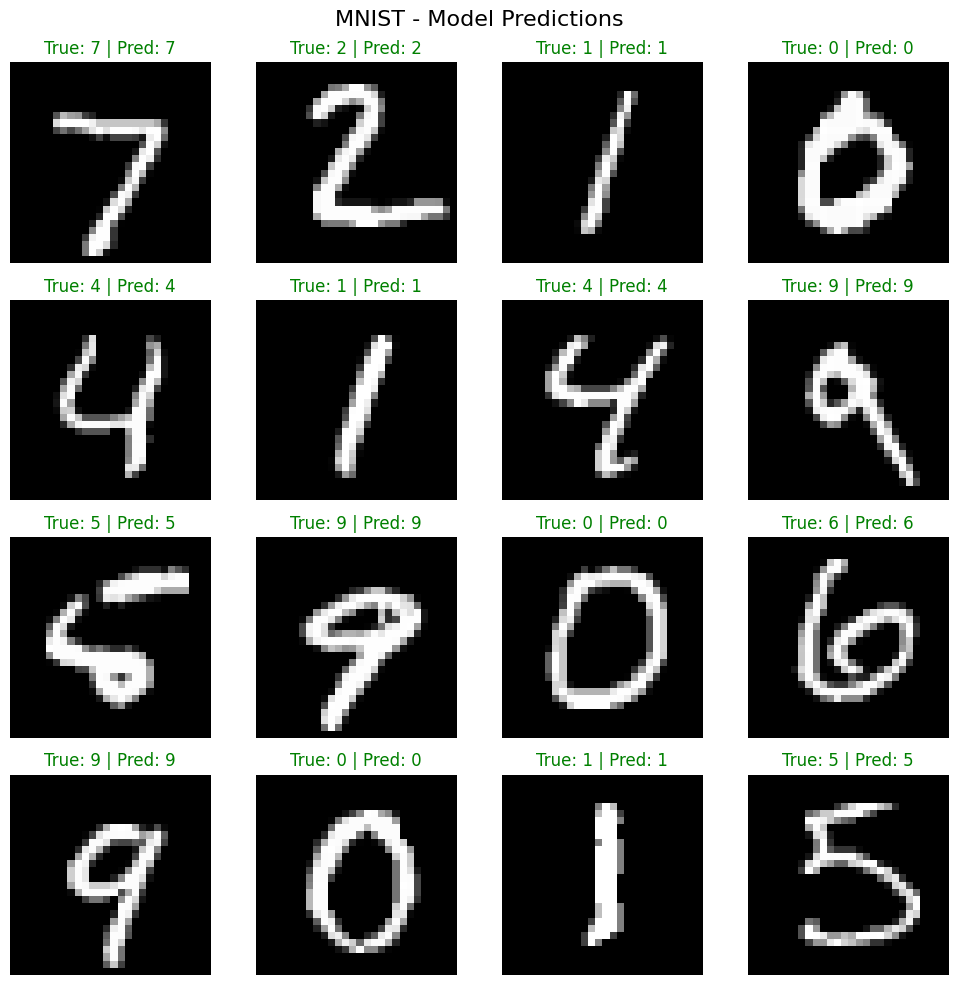

In [ ]:
# vẽ mô phỏng dự đoán
import matplotlib.pyplot as plt

images, labels = next(iter(test_loader))
images = images.to(device)
labels = labels.to(device)
model.eval()
with torch.no_grad():
    logits = model(images)
    predictions = logits.argmax(dim=1)
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    image = images[i].cpu().reshape(28, 28)
    true_label = labels[i].item()
    pred_label = predictions[i].item()
    ax.imshow(image, cmap="gray")
    ax.set_title(f"True: {true_label} | Pred: {pred_label}",
                 color="green" if true_label == pred_label else "red")
    ax.axis("off")
plt.suptitle("MNIST - Model Predictions", fontsize=16)
plt.tight_layout()
plt.show()


3.1.3 dự đoán trên hình tự vẽ

3.1.4 tải hình lên

In [1]:

from google.colab import files
from PIL import Image, ImageOps

uploaded = files.upload()
filename1 = next(iter(uploaded))

Saving số 1.png to số 1.png


3.1.5 chỉnh sửa ảnh về đen trắng và dự đoán

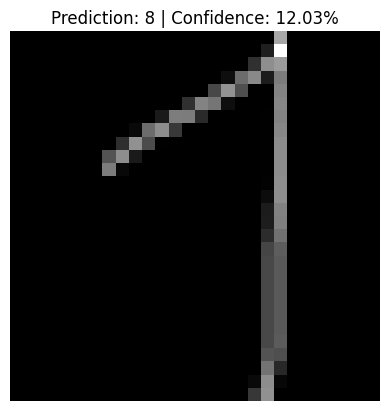

Model dự đoán: 8
Confidence: 12.03%


In [ ]:
img1 = Image.open(filename1).convert("L")
img1 = ImageOps.invert(img1)
arr1 = np.array(img1)
mask1 = arr1 > 30
ys1, xs1 = np.where(mask1)
img1 = img1.crop((xs1.min(), ys1.min(), xs1.max() + 1, ys1.max() + 1))
img1.thumbnail((28, 28))
canvas1 = Image.new("L", (28, 28), 0)
left = (28 - img1.width) // 2
top = (28 - img1.height) // 2
canvas1.paste(img1, (left, top))
arr1 = np.array(canvas1, dtype=np.float32) / 255.0
x_input = torch.from_numpy(arr1).reshape(1, 784).to(device)
model.eval()
with torch.no_grad():
    logits = model(x_input)
    probabilities = torch.softmax(logits, dim=1)
    prediction = logits.argmax(dim=1).item()
    confidence = probabilities[0, prediction].item() * 100
plt.imshow(canvas1, cmap="gray")
plt.title(f"Prediction: {prediction} | Confidence: {confidence:.2f}%")
plt.axis("off")
plt.show()
print("Model dự đoán:", prediction)
print(f"Confidence: {confidence:.2f}%")

model đã dự đoán đúng nhầm số 1 thành số 8

3.1.6 dự đoán số khác

3.1.7 tải số 5 lên

In [ ]:
uploaded = files.upload()
filename5 = next(iter(uploaded))

Saving số 5.png to số 5.png


3.1.8 điều chỉnh hình về đen trắng và dự đoán

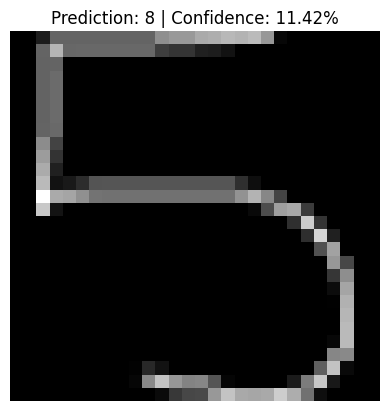

Model dự đoán: 8
Confidence: 11.42%


In [ ]:
img5 = Image.open(filename5).convert("L")
img5 = ImageOps.invert(img5)
arr5 = np.array(img5)
mask5 = arr5 > 30
ys5, xs5 = np.where(mask5)
img5 = img5.crop((xs5.min(), ys5.min(), xs5.max() + 1, ys5.max() + 1))
img5.thumbnail((28, 28))
canvas5 = Image.new("L", (28, 28), 0)
left = (28 - img5.width) // 2
top = (28 - img5.height) // 2
canvas5.paste(img5, (left, top))
arr5 = np.array(canvas5, dtype=np.float32) / 255.0
x_input = torch.from_numpy(arr5).reshape(1, 784).to(device)
model.eval()
with torch.no_grad():
    logits = model(x_input)
    probabilities = torch.softmax(logits, dim=1)
    prediction = logits.argmax(dim=1).item()
    confidence = probabilities[0, prediction].item() * 100
plt.imshow(canvas5, cmap="gray")
plt.title(f"Prediction: {prediction} | Confidence: {confidence:.2f}%")
plt.axis("off")
plt.show()
print("Model dự đoán:", prediction)
print(f"Confidence: {confidence:.2f}%")

model đã dự đoán sai số 5 thành số 8 vậy sai ở đâu mà model lại dự đoán nhầm như thế ?

3.1.9 điều chỉnh lại thông số ảnh để dự đoán

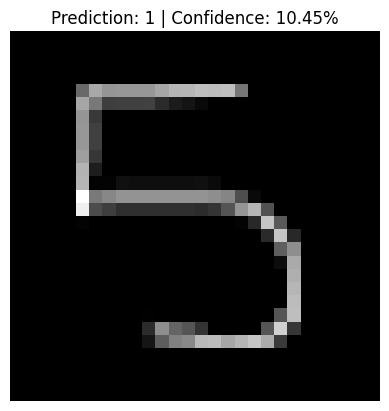

Model dự đoán: 1
Confidence: 10.45%


In [ ]:
# thay đổi lại khung để tránh bị mất nét
img5.thumbnail((20, 20))
canvas5 = Image.new("L", (28, 28), 0)
left = (28 - img5.width) // 2
top = (28 - img5.height) // 2
canvas5.paste(img5, (left, top))
arr5 = np.array(canvas5, dtype=np.float32) / 255.0
x_input = torch.from_numpy(arr5).reshape(1, 784).to(device)

model.eval()
with torch.no_grad():
    logits = model(x_input)
    probabilities = torch.softmax(logits, dim=1)
    prediction = logits.argmax(dim=1).item()
    confidence = probabilities[0, prediction].item() * 100
plt.imshow(canvas5, cmap="gray")
plt.title(f"Prediction: {prediction} | Confidence: {confidence:.2f}%")
plt.axis("off")
plt.show()
print("Model dự đoán:", prediction)
print(f"Confidence: {confidence:.2f}%")

model vẫn dự đoán sai số 5

3.2 CNN

3.2.1 xây dựng model

In [ ]:
# model
class CNN(nn.Module):
  def __init__(self):
    super().__init__()
    self.conv1 = nn.Conv2d(in_channels = 1, out_channels = 32, kernel_size = 3, stride = 1, padding = 1)
    self.relu1 = nn.ReLU()
    self.maxpool1 = nn.MaxPool2d(kernel_size = 2, stride = 2)

    self.conv2 = nn.Conv2d(in_channels = 32, out_channels = 64, kernel_size = 3, stride = 1, padding = 1)
    self.relu2 = nn.ReLU()
    self.maxpool2 = nn.MaxPool2d(kernel_size = 2, stride = 2)

    self.conv3 = nn.Conv2d(in_channels = 64, out_channels = 128, kernel_size = 3, stride = 1, padding = 1)
    self.relu3 = nn.ReLU()
    self.maxpool3 = nn.MaxPool2d(kernel_size = 2, stride = 2)

    self.flatten = nn.Flatten()
    self.linear = nn.Linear(128 * 3 * 3, 10)

  def forward(self, x):
    x = x.view(-1, 1, 28, 28)
    x = self.conv1(x)
    x = self.relu1(x)
    x = self.maxpool1(x)
    x = self.conv2(x)
    x = self.relu2(x)
    x = self.maxpool2(x)
    x = self.conv3(x)
    x = self.relu3(x)
    x = self.maxpool3(x)
    x = self.flatten(x)
    x = self.linear(x)
    return x

3.2.2 train model

In [ ]:
# train model
model = CNN()
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)

best_loss = float('inf')
patience_counter = 0
patience = 5
model.to(device)

for epoch in range(1000):
  model.train()
  total_loss = 0
  for x_batch, y_batch in train_loader:
    x_batch, y_batch = x_batch.to(device), y_batch.to(device).long()
    optimizer.zero_grad()
    y_pred = model(x_batch)
    loss = loss_fn(y_pred, y_batch)
    loss.backward()
    optimizer.step()
    total_loss += loss.item() * x_batch.size(0)
    # thêm early stopping để tránh overfitting
  train_loss = total_loss / len(train_loader.dataset)

  model.eval()
  val_loss = 0
  with torch.no_grad():
    for x_batch, y_batch in val_loader:
      x_batch, y_batch = x_batch.to(device), y_batch.to(device).long()
      y_pred = model(x_batch)
      loss = loss_fn(y_pred, y_batch)
      val_loss += loss.item() * x_batch.size(0)
  val_loss /= len(val_loader.dataset)
  if epoch % 10 == 0 :
    print(f"Epoch {epoch} - Train Loss: {train_loss:.4f} - Val Loss: {val_loss:.4f}")

  if val_loss < best_loss:
    best_loss = val_loss
    patience_counter = 0
  else:
    patience_counter += 1
    if patience_counter >= patience:
      print("Early stopping!")
      print(f"Epoch : {epoch} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")
      break

Epoch 0 - Train Loss: 0.5391 - Val Loss: 0.1013
Early stopping!
Epoch : 6 | Train Loss: 0.0407 | Val Loss: 0.1401


có vẻ model học hiệu quả hơn

3.2.3 đánh giá model

In [ ]:
model.eval()
with torch.no_grad():
  for x_test, y_test in test_loader:
    x_test = x_test.to(device)
    y_test = y_test.to(device).long()
    logits = model(x_test)
    y_pred = torch.argmax(logits, dim=1)
accuracy = (y_pred == y_test).float().mean()
print(f"Test Accuracy: {accuracy.item():.4f}")

Test Accuracy: 1.0000


3.2.4 cho model dự đoán lại các số vừa nãy

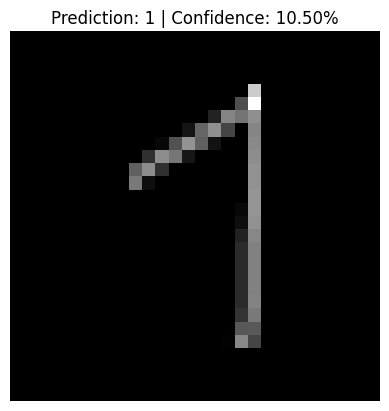

Model dự đoán: 1
Confidence: 10.50%


In [ ]:
img1.thumbnail((20, 20))
canvas1 = Image.new("L", (28, 28), 0)
left = (28 - img1.width) // 2
top = (28 - img1.height) // 2
canvas1.paste(img1, (left, top))
arr1 = np.array(canvas1, dtype=np.float32) / 255.0
x_input = torch.from_numpy(arr1).reshape(1, 784).to(device)

model.eval()
with torch.no_grad():
    logits = model(x_input)
    probabilities = torch.softmax(logits, dim=1)
    prediction = logits.argmax(dim=1).item()
    confidence = probabilities[0, prediction].item() * 100
plt.imshow(canvas1, cmap="gray")
plt.title(f"Prediction: {prediction} | Confidence: {confidence:.2f}%")
plt.axis("off")
plt.show()
print("Model dự đoán:", prediction)
print(f"Confidence: {confidence:.2f}%")

model đã dự đoán đúng số 1

dự đoán số 1 có sự khác nhau ở hai model neural vì số 1 trong data mnist chỉ là 1 dấu gạch , còn hình vẽ thì đã có thêm các đường nét. ( I và 1 ) => DNN không thể nhận ra còn CNN thì có thể nhận ra do nó học được các đặc trưng

# kết luận

DNN (Deep Neural Network):
- Làm phẳng ảnh 28 × 28 thành vector 784 pixel.
- Không giữ cấu trúc không gian của ảnh một cách tường minh sau khi flatten.
- Có thể gặp khó khăn khi phân biệt các chữ số có hình dạng gần giống nhau, dẫn đến dự đoán sai số 1 thành số 5.

CNN (Convolutional Neural Network):
- Giữ cấu trúc không gian của ảnh trong các lớp convolution.
- Tự học các đặc trưng như đường thẳng, đường cong, cạnh và hình dạng chữ số.
- Nhận diện đặc trưng hình ảnh hiệu quả hơn trong nhiều trường hợp, nên có thể dự đoán đúng số 1 mà DNN dự đoán sai.

Kết luận:
- CNN thường phù hợp với bài toán nhận diện hình ảnh hơn DNN thông thường.
- CNN có thể đạt độ chính xác cao hơn nhờ khả năng trích xuất đặc trưng không gian.